# Project data exploration - looking at relplot and scatter plots
Using a dataset that your group is consider using for the term project, let's do some data exploring of the different features in your dataset and their relationships

Group name:  
Created by NAMES (SJSU IDs):  Dan Nguyen(017066426), Nurislam Saliev, Rohan Poosala  

Last updated: 10/25/26  

Briefly describe your dataset: Dataset: It contains data about discourses on AI-driven data scientists’ job displacement on LinkedIn. It was used for a Master Dissertation, DiCEM (Pompeu Fabra University, Barcelona), year 2024-2025 (http://hdl.handle.net/10230/71874). It is also referred in the article Technological optimism or automation anxiety: how data scientists discuss AI-driven job displacement, Hipertext.net, n. 32, May 2026.  
Goal: explaining the perceptions and sentiments of data scientists - AI experts and practitioners - regarding AI's ability to displace them. To reach this goal, a sufficiently meaningful sample of 784 posts published from April 2024 to June 2025 on LinkedIn – a platform for professional development and networking – was scrutinised. With LDA topic modelling and zero-shot sentiment analysis, social media discourses on data scientists’ job displacement have been mapped.
Data is contained in a spreadsheet, with raw text of Linkedin posts (anonymized), text after processing, and calculation of probability between topics.


Import your data. If you want to mount your Google drive you can use `from google.colab import drive` and `drive.mount('/content/drive')`

## Q1: Data background
Provide a brief summary of the data including source, size of data, topic, and what the motivation behind exploring this dataset.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')
DATA_PATH = '/content/drive/MyDrive/CS133 group project/data/Dataset_LinkedIn_posts_Hipertext_32_def-1.csv'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Peek raw files
with open(DATA_PATH, encoding= "utf-8", errors='replace') as f:
  for _ in range(3):
    print(f.readline())

﻿Linkedin Raw text;LinkedIn post Text after pre-processing;Topic1 (distribution of probabilities between topics);Topic2 (distribution of probabilities between topics);Topic3 (distribution of probabilities between topics);Topic4 (distribution of probabilities between topics);Topic5 (distribution of probabilities between topics);Topic6 (distribution of probabilities between topics);Topic7 (distribution of probabilities between topics)

"I bumped into a friend who asked me how things were going. How's the family? And what project have I been working on recently? When I mentioned AI, he was curious but expressed that he didn't know that much about what AI is? What could it do? Or how AI did it? So I explained:





In [ ]:
df = pd.read_csv(DATA_PATH, sep=';', decimal=',', encoding='utf-8')
df = df.dropna(how='all') # drop empty rows
df

,Linkedin Raw text,LinkedIn post Text after pre-processing,Topic1 (distribution of probabilities between topics),Topic2 (distribution of probabilities between topics),Topic3 (distribution of probabilities between topics),Topic4 (distribution of probabilities between topics),Topic5 (distribution of probabilities between topics),Topic6 (distribution of probabilities between topics),Topic7 (distribution of probabilities between topics)
0,I bumped into a friend who asked me how things...,bump friend who thing family project work rece...,0.9908,0.0015,0.0015,0.0015,0.0015,0.0015,0.0015
1,The Future of Data Analytics: Will AI Tools Re...,future analytic ai tool replace ai tool chatgp...,0.9933,0.0011,0.0011,0.0011,0.0011,0.0011,0.0011
2,I've been really interested to see the enormou...,really interested enormous wave discussion aro...,0.9643,0.0324,0.0007,0.0007,0.0007,0.0007,0.0007
3,???? ???????? ?????????????????????? ?????????...,ai generate code snippet second take build sca...,0.3223,0.0008,0.0008,0.0008,0.6736,0.0008,0.0008
4,Reinventing Yourself in the Age of AI \n\nAs a...,reinvent age ai artificial intelligence contin...,0.6730,0.0009,0.0009,0.0009,0.0009,0.0009,0.3223
...,...,...,...,...,...,...,...,...,...
779,Using AI for data analysis and storytelling ca...,ai analysis storytelling incredibly beneficial...,0.9909,0.0015,0.0015,0.0015,0.0015,0.0015,0.0015
780,Replace Data Analysts in 5 Years? Don't Bet on...,replace not bet sure ais automate task steal j...,0.7069,0.0016,0.0016,0.0016,0.2851,0.0016,0.0016
781,"In my opinion, AI shouldn�t be seen as a threa...",opinion ai not threat tool evolve role boost h...,0.9693,0.0051,0.0051,0.0051,0.0051,0.0051,0.0051
782,Curious about how Artificial Intelligence (AI)...,curious artificial intelligence ai shape workf...,0.9868,0.0022,0.0022,0.0022,0.0022,0.0022,0.0022


In [ ]:
# See the real column names
print(df.columns.tolist())

# Text columns are the non-numeric ones, topic columns are the numeric ones
text_cols = df.select_dtypes(include='object').columns.tolist()
topic_cols = df.select_dtypes(include='number').columns.tolist()

TEXT_COL = text_cols[0]       # raw post
TOPIC_X = topic_cols[0]       # first topic
TOPIC_Y = topic_cols[1]       # second topic
DATE_COL = None               # no quotes

df['post_length'] = df[TEXT_COL].astype(str).str.split().str.len()
df['dominant_topic'] = df[topic_cols].idxmax(axis=1)

# Use a sentiment column if one exists, otherwise use dominant topic
sent_matches = [c for c in df.columns if 'sentiment' in c.lower()]
SENTIMENT_COL = sent_matches[0] if sent_matches else 'dominant_topic'

print('Text column:', TEXT_COL)
print('Topic columns:', topic_cols)
print('Category column used for color:', SENTIMENT_COL)

['Linkedin Raw text', 'LinkedIn post Text after pre-processing', 'Topic1 (distribution of probabilities between topics)', 'Topic2 (distribution of probabilities between topics)', 'Topic3 (distribution of probabilities between topics)', 'Topic4 (distribution of probabilities between topics)', 'Topic5 (distribution of probabilities between topics)', 'Topic6 (distribution of probabilities between topics)', 'Topic7 (distribution of probabilities between topics)']
Text column: Linkedin Raw text
Topic columns: ['Topic1 (distribution of probabilities between topics)', 'Topic2 (distribution of probabilities between topics)', 'Topic3 (distribution of probabilities between topics)', 'Topic4 (distribution of probabilities between topics)', 'Topic5 (distribution of probabilities between topics)', 'Topic6 (distribution of probabilities between topics)', 'Topic7 (distribution of probabilities between topics)']
Category column used for color: dominant_topic


In [ ]:
import re

# Rename text columns
df = df.rename(columns={
    'Linkedin Raw text': 'raw_text',
    'LinkedIn post Text after pre-processing': 'clean_text'
})

# Rename any column containing "Topic<number>" to just "Topic<number>"
new_cols = {}
for c in df.columns:
    m = re.search(r'Topic\s*(\d+)', str(c), flags=re.IGNORECASE)
    if m:
        new_cols[c] = f'Topic{m.group(1)}'
df = df.rename(columns=new_cols)

topic_cols = [f'Topic{i}' for i in range(1, 8)]
print('Columns now:', df.columns.tolist())

# Make sure topic values are numbers (handles "0,9643" style)
df[topic_cols] = df[topic_cols].apply(
    lambda s: pd.to_numeric(s.astype(str).str.replace(',', '.'), errors='coerce'))

topic_names = {
    'Topic1': 'Will AI replace us?',
    'Topic2': 'AutoML automating ML',
    'Topic3': 'Vibe coding with GenAI',
    'Topic4': 'ChatGPT doing analysis',
    'Topic5': 'LLM agents at work',
    'Topic6': 'Juniors and citizen devs',
    'Topic7': 'Engineering skills for AI era'
}
topic_order = list(topic_names.values())

df['post_length'] = df['raw_text'].astype(str).str.split().str.len()
df['dominant_topic'] = df[topic_cols].idxmax(axis=1).map(topic_names)
df['topic_strength'] = df[topic_cols].max(axis=1)

print(df['dominant_topic'].value_counts())

Columns now: ['raw_text', 'clean_text', 'Topic1', 'Topic2', 'Topic3', 'Topic4', 'Topic5', 'Topic6', 'Topic7', 'post_length', 'dominant_topic']
dominant_topic
Will AI replace us?              642
LLM agents at work                67
AutoML automating ML              23
ChatGPT doing analysis            17
Vibe coding with GenAI            13
Engineering skills for AI era     11
Juniors and citizen devs          11
Name: count, dtype: int64


`Source`: The dataset comes from CORA, the research data repository of Universitat Pompeu Fabra in Barcelona (DOI: 10.34810/DATA3307). It was created by Olga Samokhina for a Master’s dissertation and is used in the 2026 article Technological optimism or automation anxiety: how data scientists discuss AI driven job displacement (Hipertext.net, no. 32). It is open access under a CC0 license.

`Size`: The data is a single CSV file (about 1.7 MB) with 784 LinkedIn posts and 9 columns: the raw post text, the post text after preprocessing, and 7 columns giving the probability that each post belongs to each of 7 topics found with LDA topic modeling.

`Topic`: The posts were published on LinkedIn between April 2024 and June 2025 by data scientists and AI practitioners discussing whether AI could replace their jobs. Topics range from the broad question of AI replacing human workers to specific themes like AutoML, LLM agents, vibe coding, and how junior roles may change.

`Motivation`: With growing talk of an AI bubble and a rise in layoffs blamed on AI, many workers feel uncertain about their futures, and job insecurity is a known source of stress and anxiety. Data scientists are an interesting group to study because they build and understand these tools better than most. We want to explore which concerns come up most in their posts, how strongly each post focuses on a single theme, and whether the people closest to AI sound worried or confident about being replaced. As data science students about to enter this job market, the question is also personal for us.

[Dataset for article Technological optimism or automation anxiety: how data scientists discuss AI-driven job displacement](https://b2find.eudat.eu/dataset/90374793-6c29-5121-8171-2c7ebe2f25c2)  
[Dataset](https://dataverse.csuc.cat/dataset.xhtml?persistentId=doi:10.34810/DATA3307)

### Q2: Show the number of missing data in each column of the dataframe
If you have missing data, how much? which column(s)? Do you think it will impact your output?

In [ ]:
missing = df.isnull().sum()
missing_pct = (missing/ len(df) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_percent': missing_pct})

,missing_count,missing_percent
raw_text,0,0.0
clean_text,0,0.0
Topic1,0,0.0
Topic2,0,0.0
Topic3,0,0.0
Topic4,0,0.0
Topic5,0,0.0
Topic6,0,0.0
Topic7,0,0.0
post_length,0,0.0


### Q3: Show the data type for each column of the dataframe
Is the data type as expected? Is it clear what the content/value of each column is?

In [ ]:
df.shape

(784, 12)

In [ ]:
df.dtypes

,0
raw_text,object
clean_text,object
Topic1,float64
Topic2,float64
Topic3,float64
Topic4,float64
Topic5,float64
Topic6,float64
Topic7,float64
post_length,int64


### Q4: Your own question using `relplot()`
Do posts that lean strongly toward one topic lean away from another, and does that differ by sentiment?

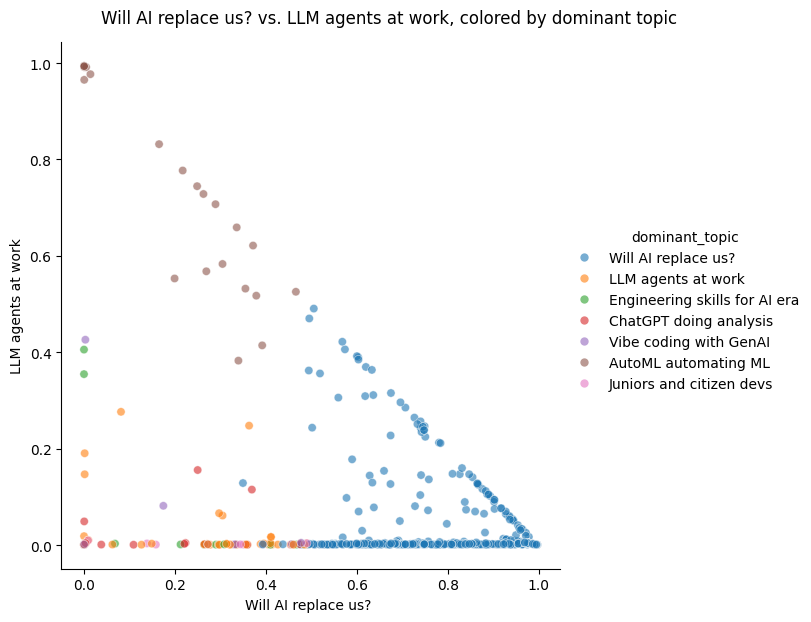

In [ ]:
g = sns.relplot(data=df, x='Topic1', y='Topic2', hue='dominant_topic',
                kind='scatter', alpha=0.6, height=6)
g.set_axis_labels('Will AI replace us? ', 'LLM agents at work')
g.figure.suptitle('Will AI replace us? vs. LLM agents at work, colored by dominant topic', y=1.03)
plt.show()

### Q5: Your own question using `catplot()`
Do data scientists sound more optimistic or anxious about AI taking their jobs, and how does sentiment spread across topics?

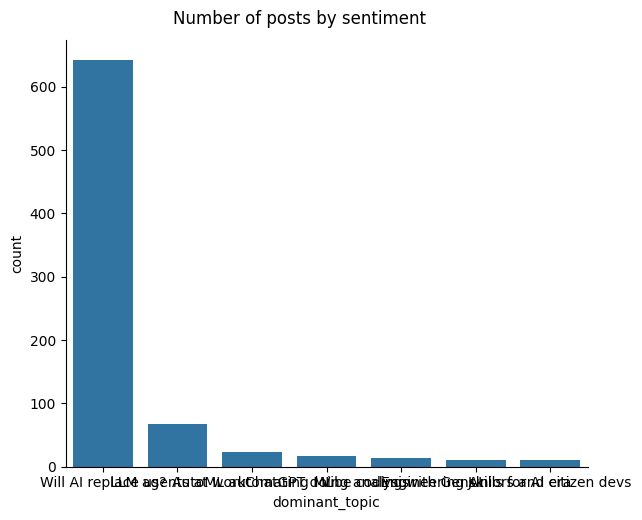

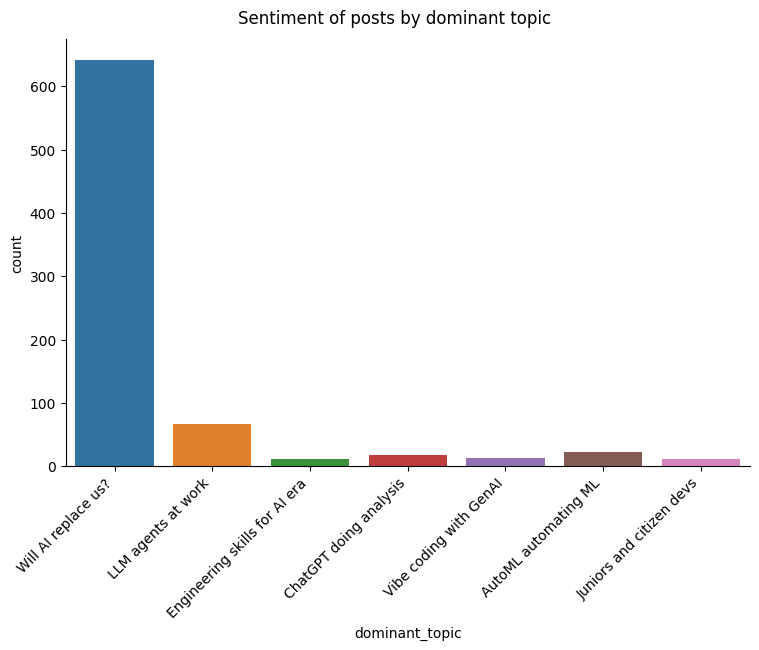

In [ ]:
g = sns.catplot(data=df,
                x=SENTIMENT_COL,
                kind='count',
                order=df[SENTIMENT_COL].value_counts().index,
                height=5,
                aspect=1.2)
g.figure.suptitle('Number of posts by sentiment', y=1.03)
plt.show()

if 'dominant_topic' in df.columns:
    g = sns.catplot(data=df, x='dominant_topic', hue=SENTIMENT_COL,
                    kind='count', height=5, aspect=1.6)
    g.set_xticklabels(rotation=45, ha='right')
    g.figure.suptitle('Sentiment of posts by dominant topic', y=1.03)
    plt.show()

### Q6: Create a plot with small multiples plots
Select two features from your dataset and show the relationship between the features with an additional feature as the single category. Organize the multiple plots to have 3 plots per row. Set the `height` of the plot to 5 and the size the of data point to 20. Include a meaningful title in the plot.

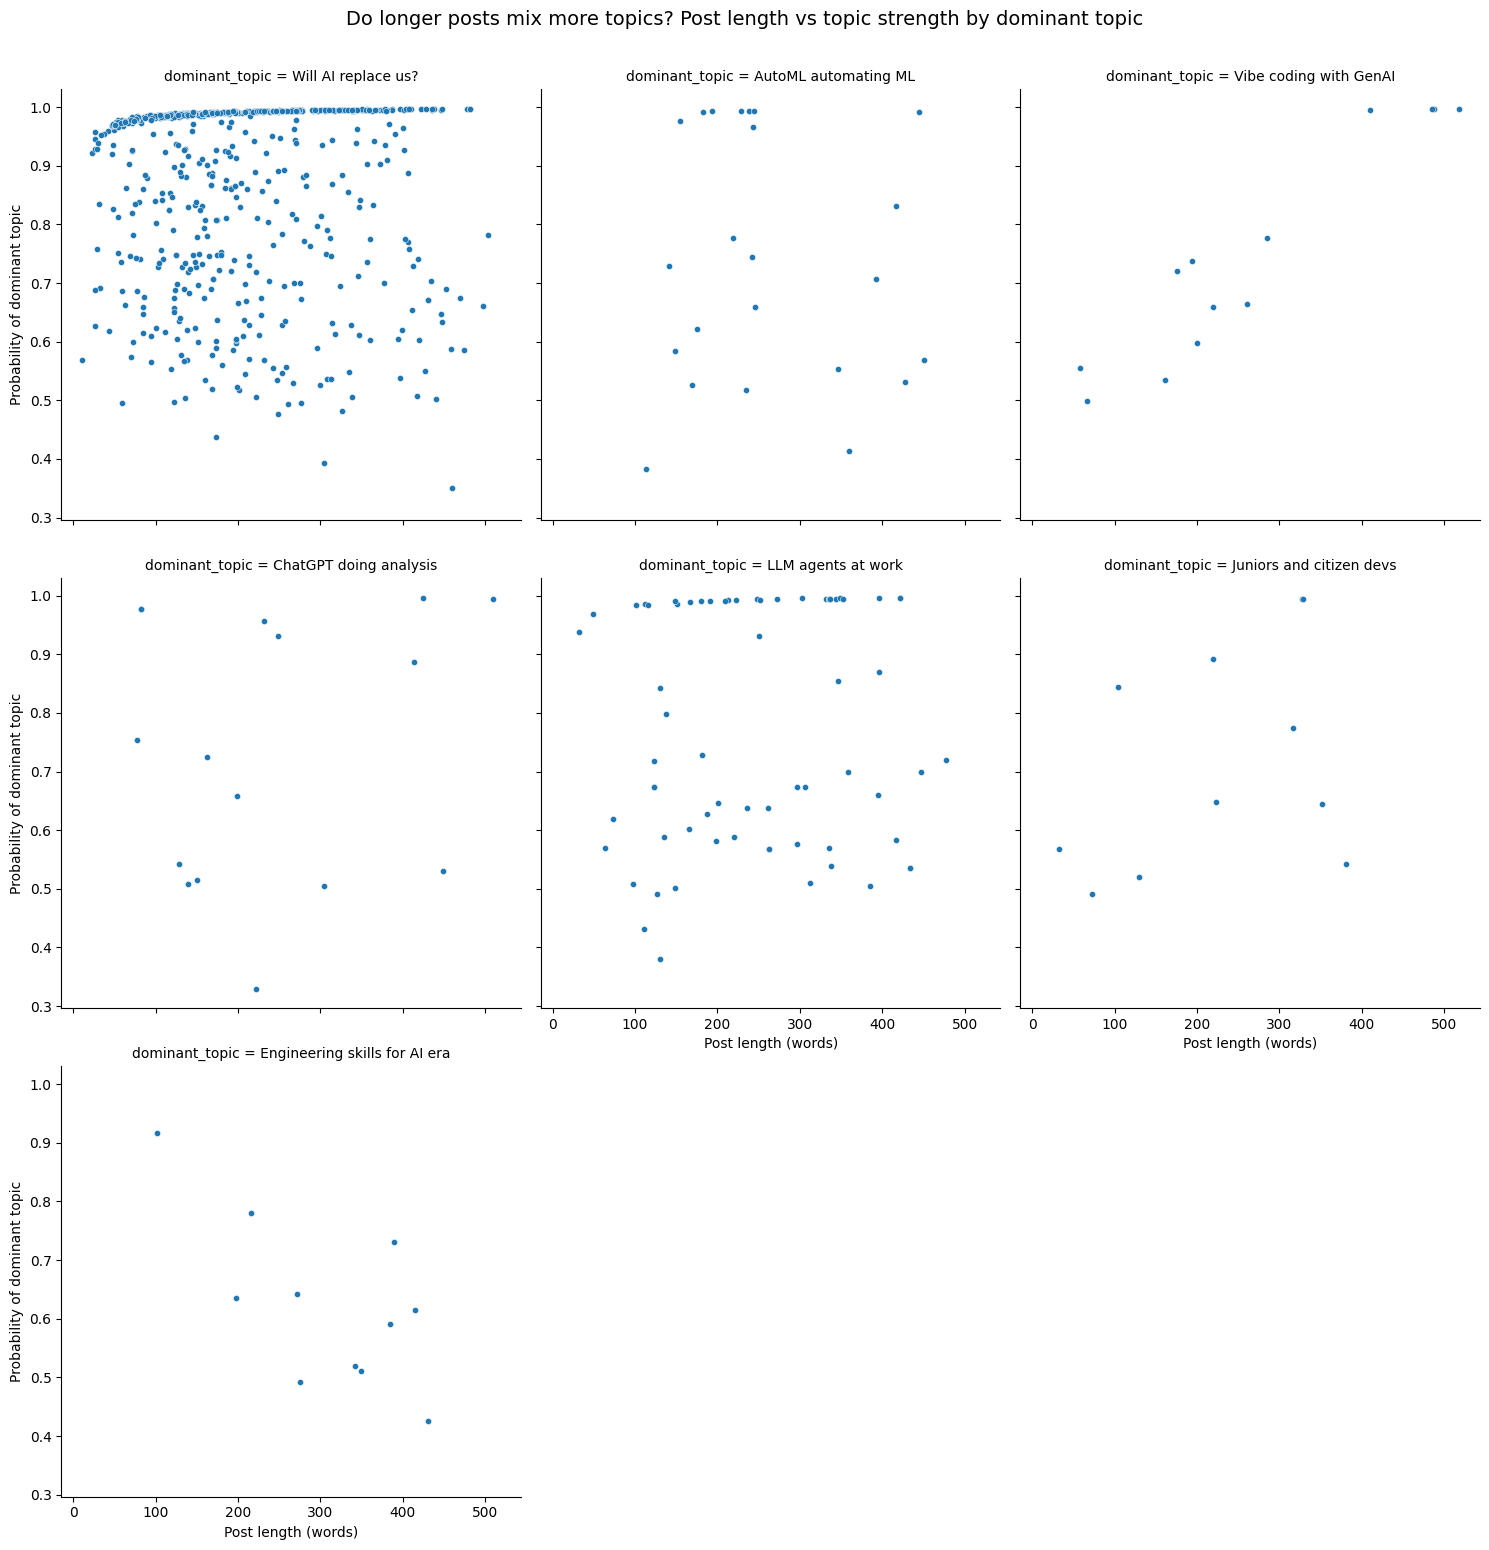

In [ ]:
g = sns.relplot(
    data=df,
    x='post_length',
    y='topic_strength',
    col='dominant_topic',
    col_order=topic_order,
    col_wrap=3,
    height=5,
    s=20,
    kind='scatter'
)
g.set_axis_labels('Post length (words)', 'Probability of dominant topic')
g.figure.suptitle('Do longer posts mix more topics? Post length vs topic strength by dominant topic',
                  y=1.03, fontsize=14)
plt.show()